# 7c. E3SM hindcasts in the XRO state space

Third of the four XRO notebooks (7a validation → 7b events → **7c E3SM state** → 7d recharge).
The ten-variable XRO state vector is computed from every hindcast member and compared with
observations and with the XRO benchmark of 7b.

**Anomalies.** Model anomalies remove the Reanalysis (BruteForce) 1981-2010 lead-time
climatology (`CLIM_METHOD`, see the README: Feb and Aug starts use the observed target-month
climatology plus the Reanalysis drift at the same lead). Observations are relative to their own
1981-2010 monthly climatology. The two anomaly definitions share the base period but not the
reference system, so an error at lead 0 can be either a real initial-state difference or a
difference between the reanalysis that initializes E3SM and the observational product (CFSR
ocean vs EN4 for *h*, in particular).

**h.** 5°S-5°N, 120°E-80°W mean 0-700 m heat content (GJ m⁻²), the equatorial Pacific OHC700
recharge proxy (not WWV). The model field `oceanHeatContentSfcTo700m` is converted from J per
native cell to J m⁻² (`rc.FIELDS["OHC700"]`). Its absolute values (about 807 GJ m⁻² vs 37 in EN4)
show a 0 K vs 0 °C reference temperature; the constant cancels in anomalies, but if MPAS integrates
from the moving sea surface, sea-level anomalies add about 0.1 GJ m⁻² per 0.1 m in phase with
recharge. Open check before interpreting small *h* differences.

**Sections:**

1. State-vector plumes: observed, every case (ensemble mean and `SPREAD` percentiles of the
   members) and XRO (deterministic and stochastic `SPREAD` percentiles; same percentiles for both).
2. Error decomposition by lead: total error B(L) = F(L) − O(L) and its change after the start
   month, G(L) = B(L) − B(0). B(0) is the start-month discrepancy (initial state or reference);
   G(L) is the error in the evolution after it.
3. Summary heat maps: start-month error B(0) and first-season evolution error (mean of G over
   `EVOL_LEADS`), standardized by the observed standard deviation.
4. Growth from the start month: T(L) − T(0) and h(L) − h(0) for observed, E3SM and XRO.
5. Peak-season summary with common uncertainty ranges.

Leads: 0 = start month (the hindcasts' first monthly mean). XRO starts from the month before (its
lead −1), so its lead-0 error is already a one-month forecast error.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from datetime import datetime

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from IPython.display import display

from util import rtenso_case as rc
from util import xro_case as xc
from util import pubfig as pf

pf.use_style()

### Run controls

In [2]:
NOTEBOOK = "7c_e3sm_xro_state"
derivation_mode = "auto"
CLIM_METHOD = "lead_drift"          # Feb/Aug drift correction (see README)
SPREAD = xc.XRO_SETUP["spread"]     # percentiles of E3SM members and XRO stochastic copies
DECOMP_VARS = ["Nino34", "WWV", "NPMM", "SPMM", "IOD"]   # section 2
DECOMP_LEADS = 12                   # leads shown in section 2
EVOL_LEADS = (1, 3)                 # leads averaged for the first-season evolution error (section 3)
OUTDIR = rc.output_dir(NOTEBOOK, "data")
print("figures ->", rc.figure_dir(NOTEBOOK))

figures -> /global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures


In [3]:
%%time
X = xc.obs_state(mode=derivation_mode)
FITS = {year: xc.fit_xro(X, event["train"]) for year, event in xc.EVENTS.items()}
XRO_FC = {(year, init): fc for year, event in xc.EVENTS.items() for init in event["init_months"]
          if (fc := xc.event_forecast(FITS[year], year, init)) is not None}
XRO_CAL = {key: xc.calibrated_stoch(X, *key, fc["stoch"], mode=derivation_mode) for key, fc in XRO_FC.items()}
FC_X = xc.hindcast_states(method=CLIM_METHOD, mode=derivation_mode)
# Observed s.d. of each variable (detrended, training years) for standardized errors
SD = {year: FITS[year]["X_dt"].sel(time=slice(f"{e['train'][0]}-01", f"{e['train'][1]}-12")).std("time")
      for year, e in xc.EVENTS.items()}
for (year, case, init), ds in FC_X.items():
    print(f"[{year} {case} init{init:02d}] {ds.sizes['member']} members; lead 0 Niño3.4 {float(ds['Nino34'].isel(lead=0).mean()):+.2f} °C, "
          f"h {float(ds['WWV'].isel(lead=0).mean()):+.2f} GJ m-2")
for var in ("Nino34", "WWV"):
    print(f"{xc.short(var)} observed through {'-'.join(f'{v:02d}' for v in xc.last_observed(X, var))}")

[2026 Reanalysis-FOSIRL init02] not available
[2026 Reanalysis-FOSIRL init05] not available
[2026 Reanalysis-FOSIRL init08] not available
[2026 Reanalysis-FOSIRL init11] not available
[2015 Reanalysis-CLIM init02] 10 members; lead 0 Niño3.4 +0.83 °C, h +0.16 GJ m-2
[2015 Reanalysis-CLIM init05] 10 members; lead 0 Niño3.4 +1.27 °C, h +0.49 GJ m-2
[2015 Reanalysis-CLIM init08] 10 members; lead 0 Niño3.4 +1.85 °C, h +0.39 GJ m-2
[2015 Reanalysis-CLIM init11] 10 members; lead 0 Niño3.4 +2.76 °C, h +0.46 GJ m-2
[2015 Reanalysis-OBS init02] 10 members; lead 0 Niño3.4 +0.84 °C, h +0.17 GJ m-2
[2015 Reanalysis-OBS init05] 10 members; lead 0 Niño3.4 +1.30 °C, h +0.50 GJ m-2
[2015 Reanalysis-OBS init08] 10 members; lead 0 Niño3.4 +1.85 °C, h +0.38 GJ m-2
[2015 Reanalysis-OBS init11] 10 members; lead 0 Niño3.4 +2.76 °C, h +0.45 GJ m-2
[2015 Reanalysis-NSIDC init02] 10 members; lead 0 Niño3.4 +0.82 °C, h +0.16 GJ m-2
[2015 Reanalysis-NSIDC init05] 10 members; lead 0 Niño3.4 +1.29 °C, h +0.50 GJ m-

In [4]:
def to_dt(times):
    return [datetime(t.year, t.month, 15) for t in np.atleast_1d(times)]


def cases_for(year, init):
    return [case for case in xc.CASES if (year, case, init) in FC_X]


def time_axis(ax, year):
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7)))
    ax.xaxis.set_minor_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
    ax.set_xlim(datetime(year - 1, 12, 1), datetime(year + 2, 2, 28))


LO, HI = SPREAD

## 1. State-vector plumes

One figure per start. Black: observed. Colours: each case's ensemble mean with the `SPREAD`
percentile range of its members shaded (10 members, so the range is close to min-max). Purple
dashed: deterministic XRO with its stochastic `SPREAD` range (overconfident, 7a). Feb 2026:
`Reanalysis-CLIM` and `Reanalysis-OBS` are identical runs, so CLIM is hidden under OBS.
Thin solid purple lines (Niño3.4 and *h*): XRO's range after the cross-validated spread calibration of 7a
section 8; it is the fairer comparison with the E3SM member range.

/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2015_state_vector_init02.pdf


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2015_state_vector_init02.png


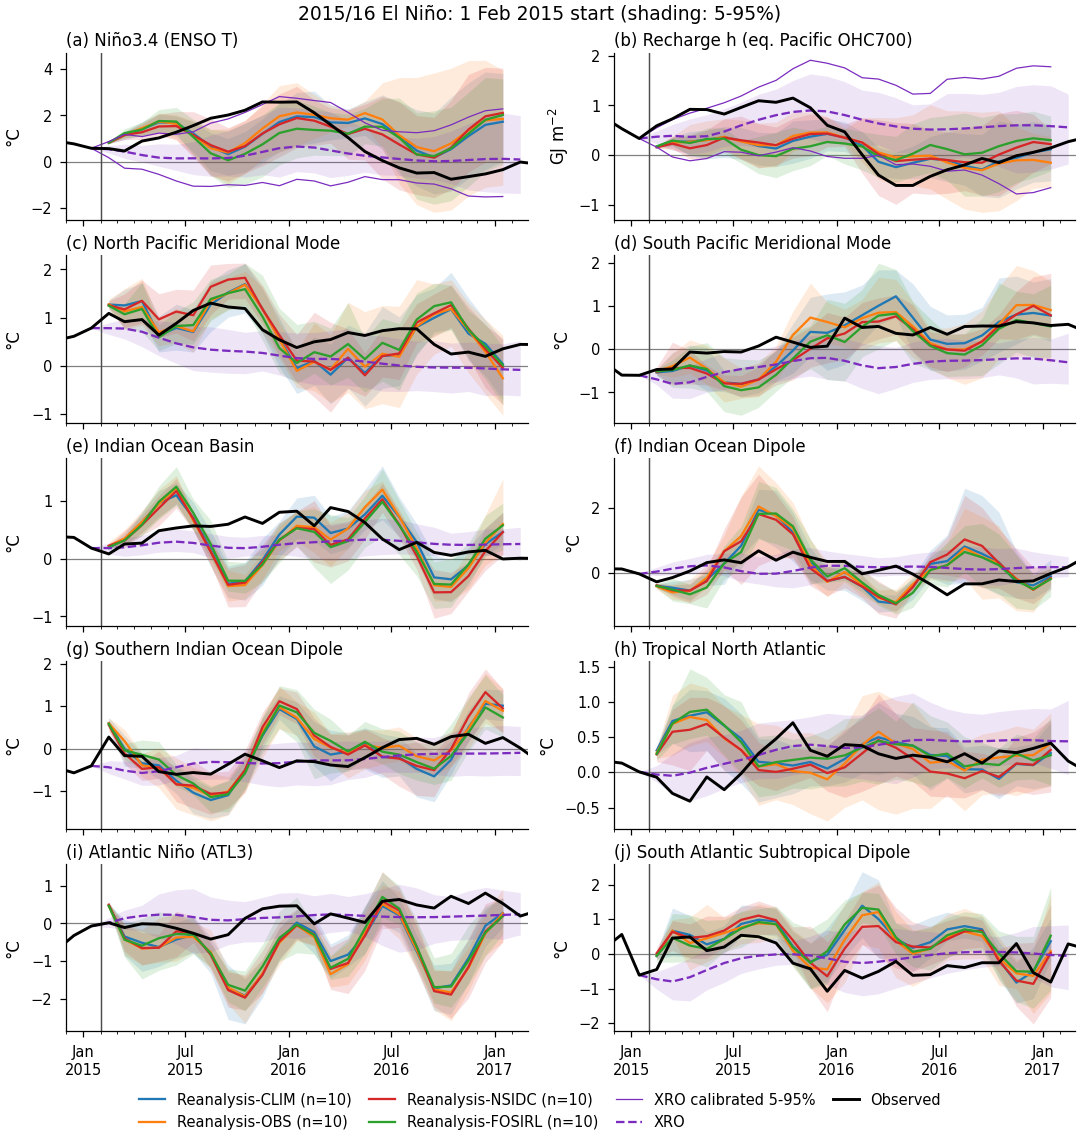

/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2015_state_vector_init05.pdf


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2015_state_vector_init05.png


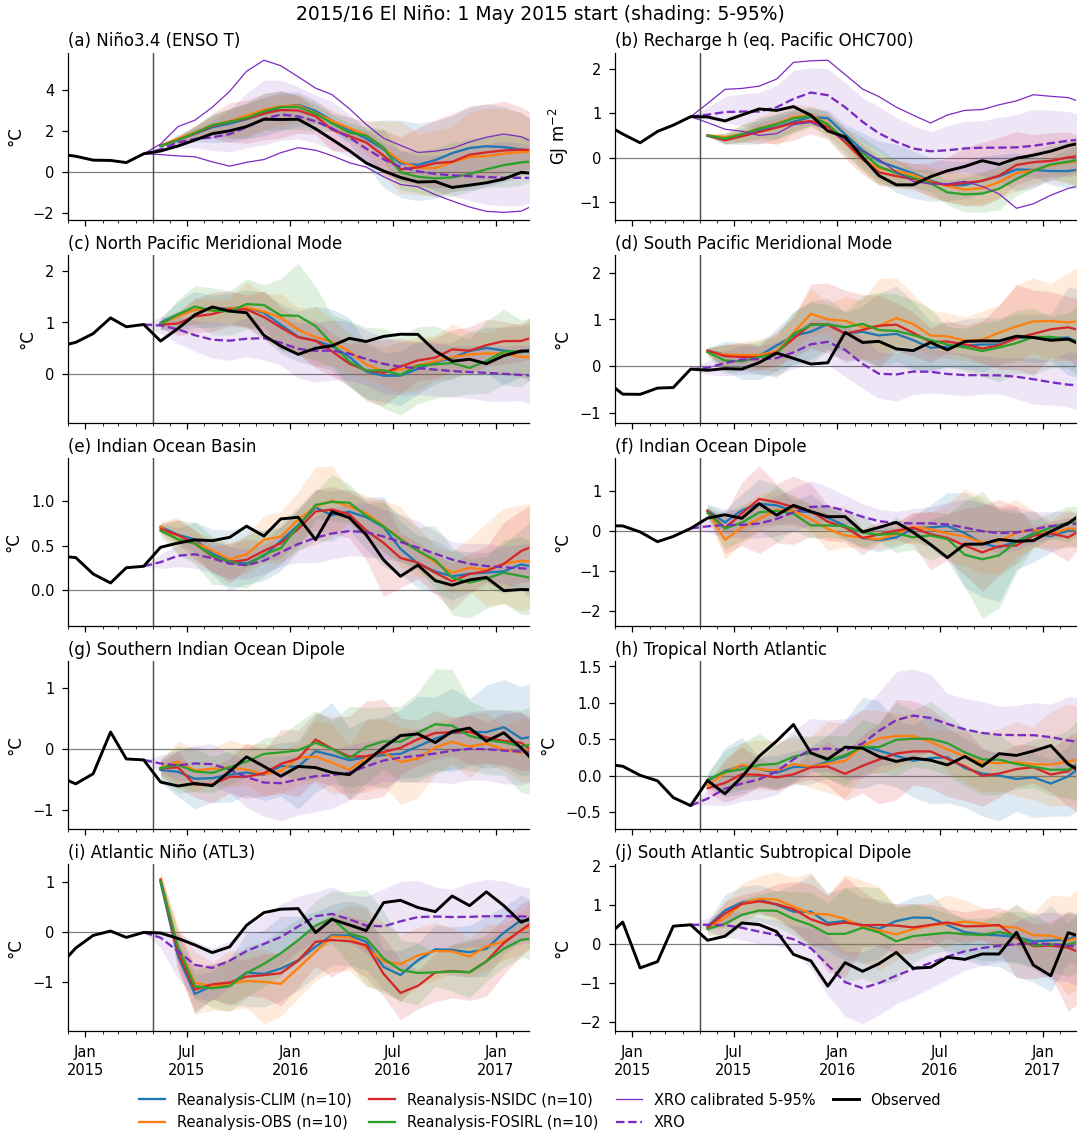

/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2015_state_vector_init08.pdf


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2015_state_vector_init08.png


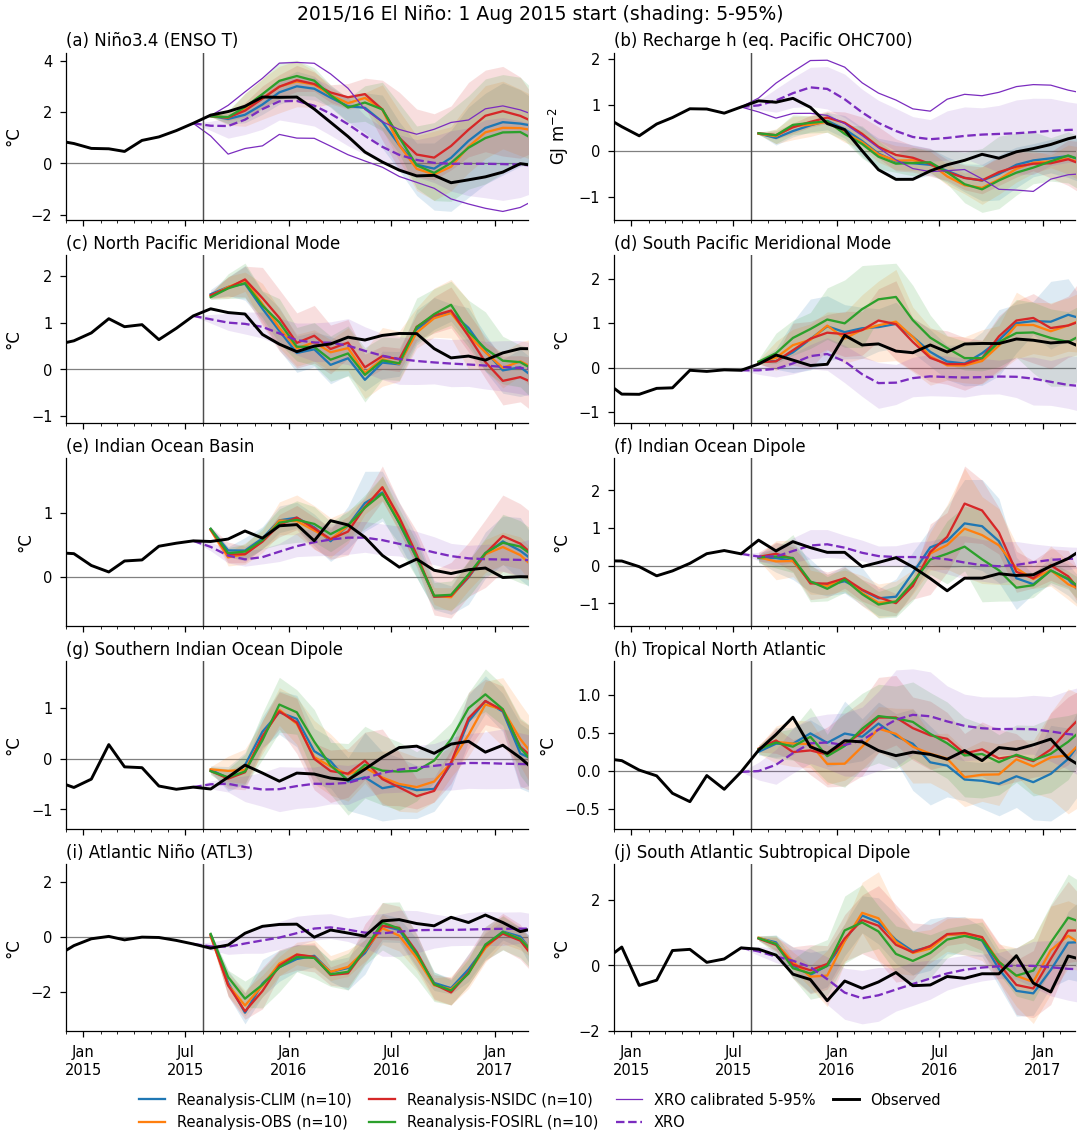

/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2015_state_vector_init11.pdf


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2015_state_vector_init11.png


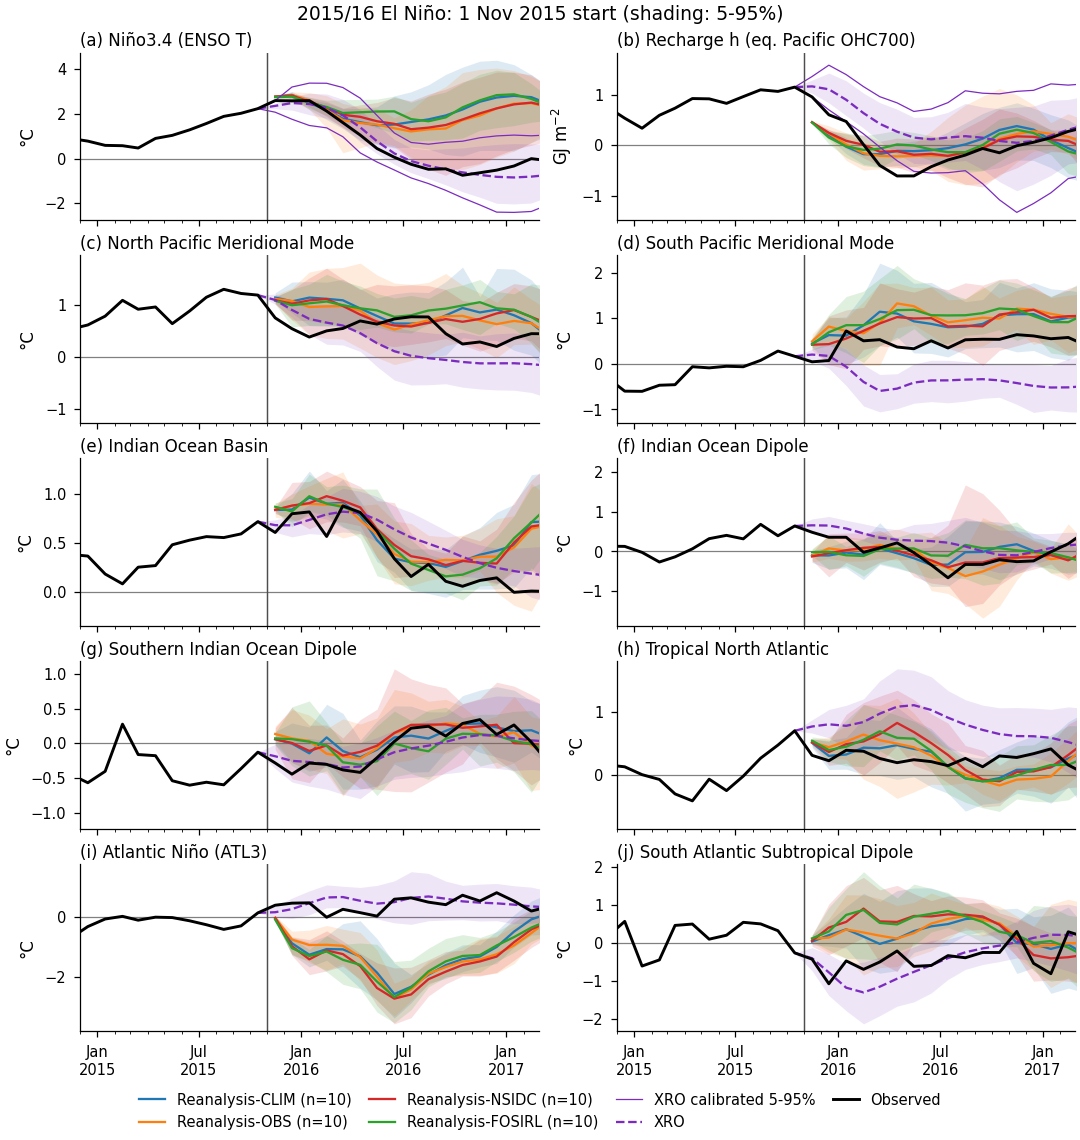

/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2026_state_vector_init02.pdf


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2026_state_vector_init02.png


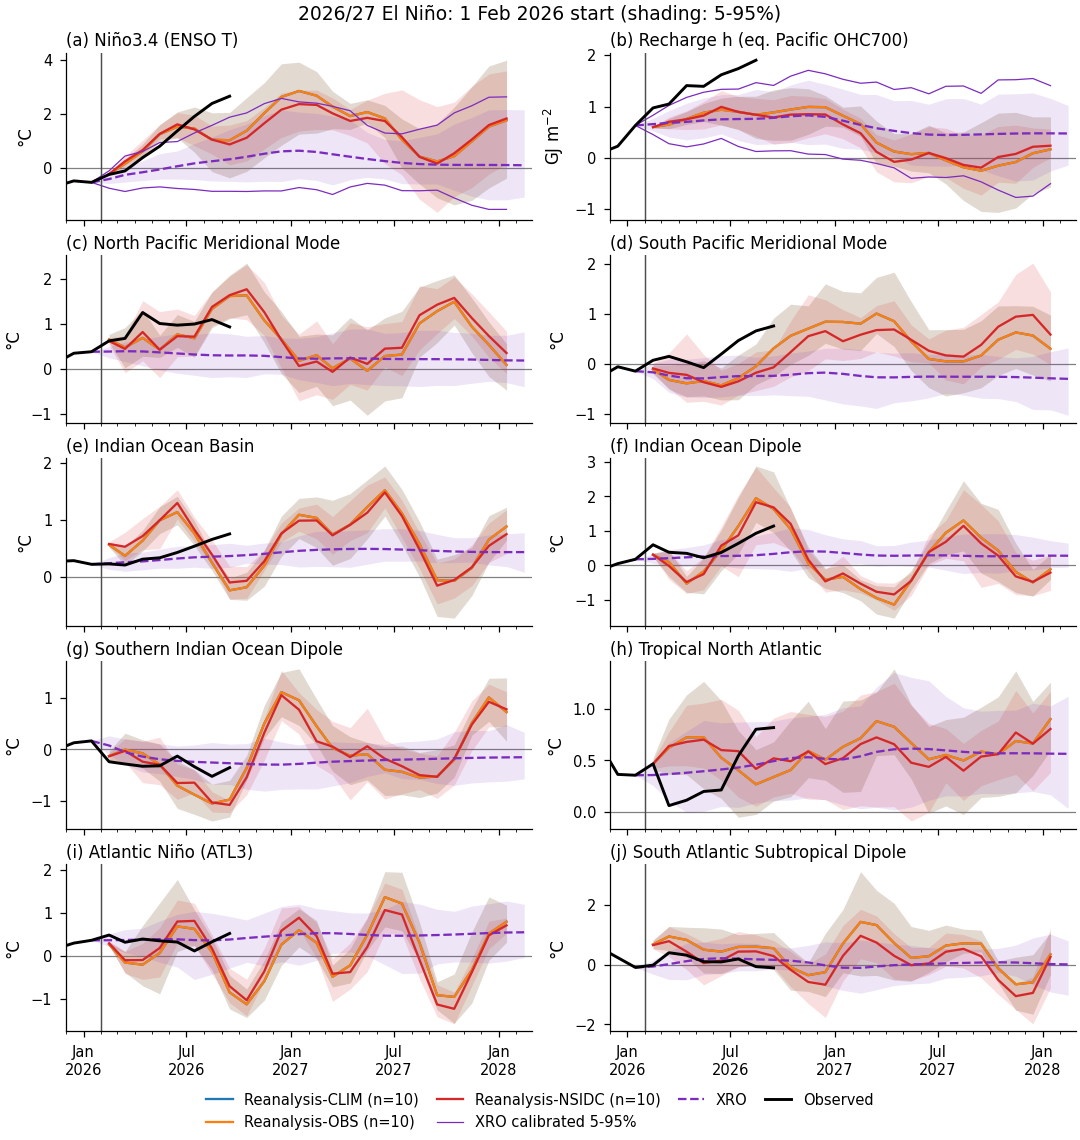

/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2026_state_vector_init05.pdf


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2026_state_vector_init05.png


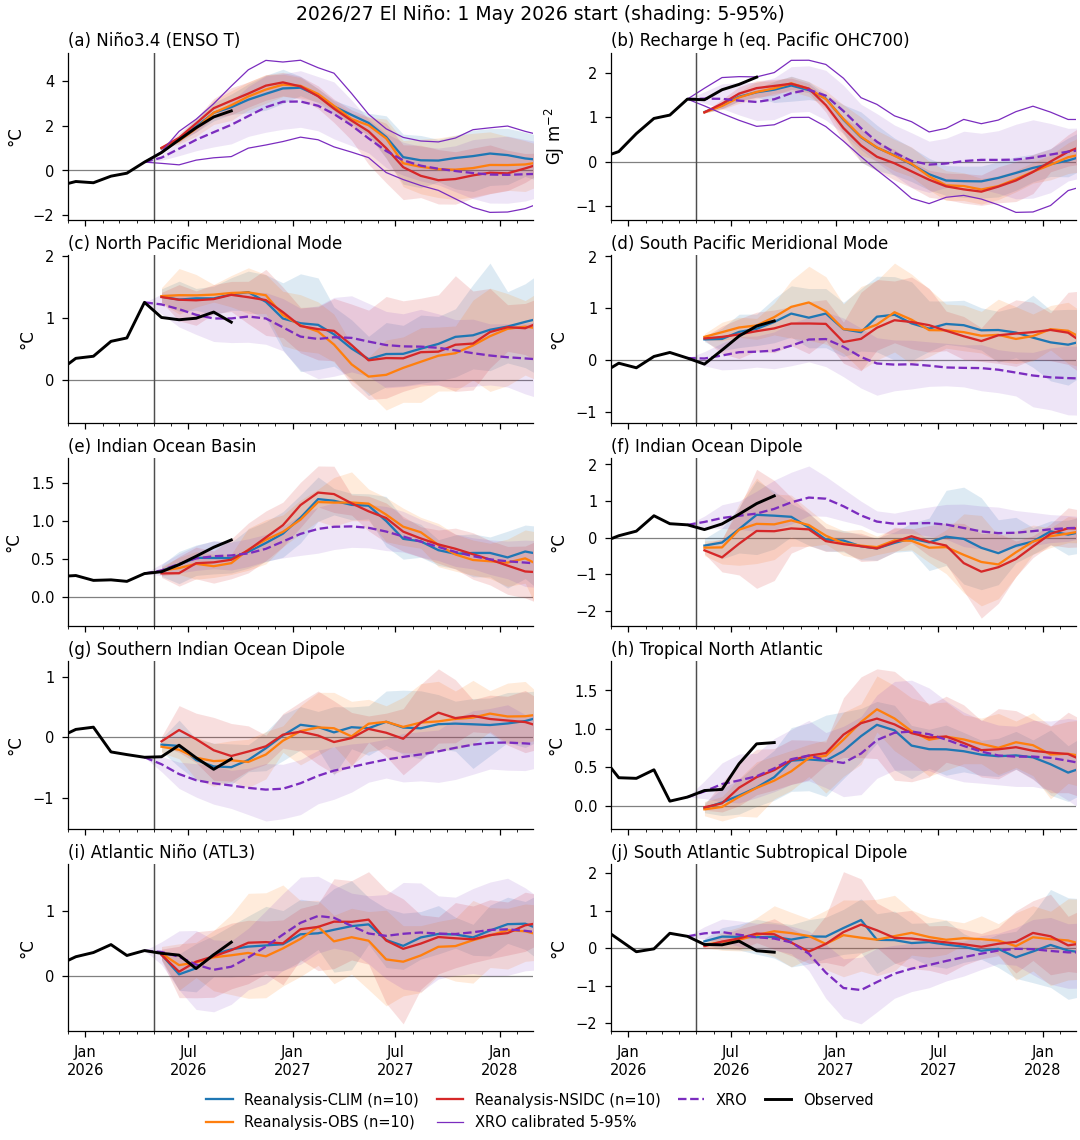

/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2026_state_vector_init08.pdf


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2026_state_vector_init08.png


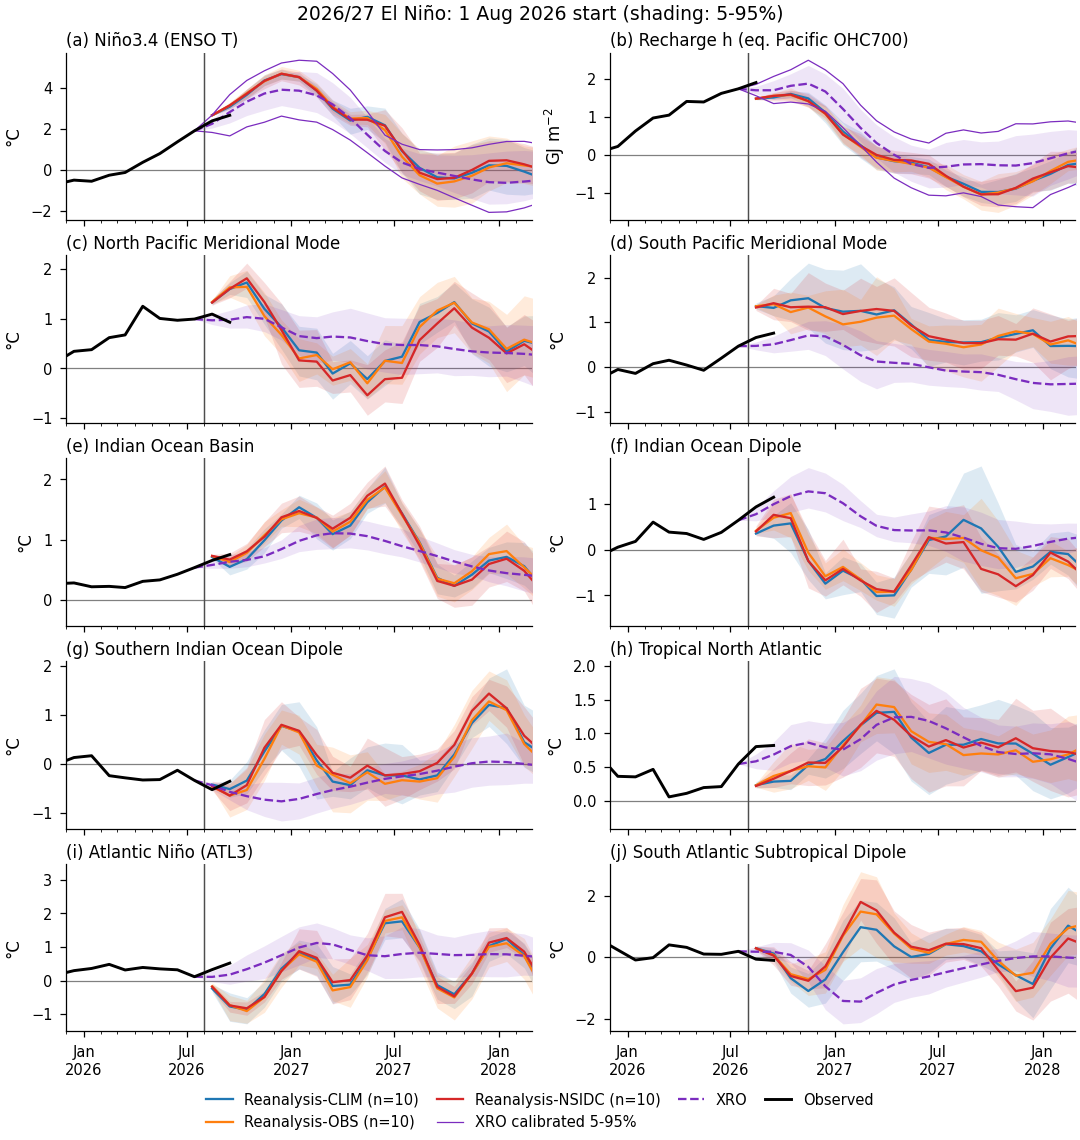

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2026_state_vector_init11.pdf


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2026_state_vector_init11.png


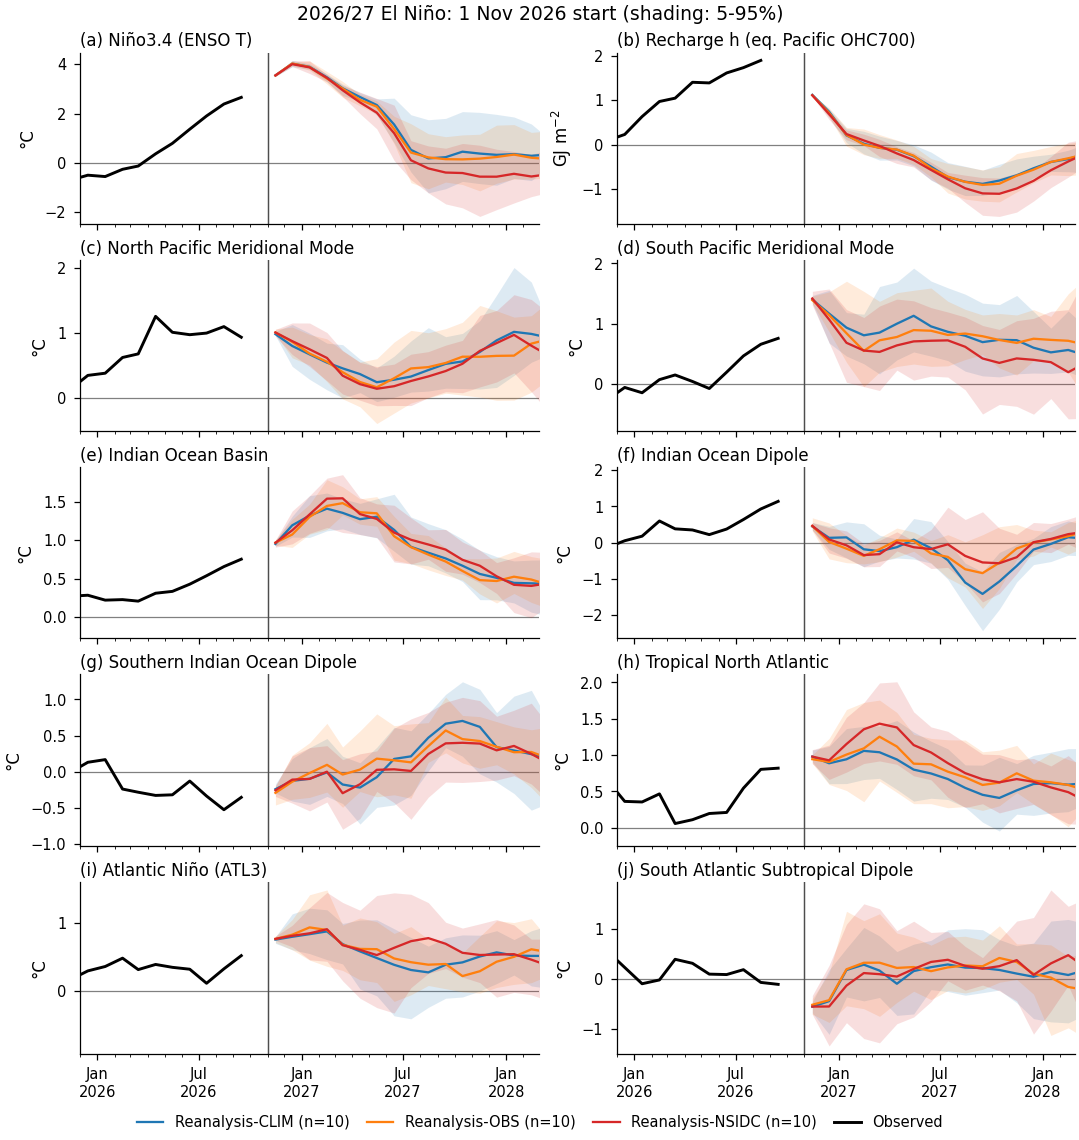

In [5]:
def plot_state(year, init):
    obs = X.sel(time=slice(f"{year - 1}-10", f"{year + 2}-03"))
    fig, axes = plt.subplots(5, 2, figsize=(pf.WIDTH["double"], 7.6), sharex=True)
    xfc = XRO_FC.get((year, init))
    for k, (ax, var) in enumerate(zip(axes.flat, xc.XRO_VARS)):
        for case in cases_for(year, init):
            ds, color = FC_X[(year, case, init)][var], xc.CASES[case]["color"]
            x = to_dt(ds["time"].values)
            ax.fill_between(x, ds.quantile(LO / 100, "member"), ds.quantile(HI / 100, "member"), color=color, alpha=0.15, lw=0)
            ax.plot(x, ds.mean("member"), color=color, lw=1.1, label=f"{case} (n={ds.sizes['member']})")
        if xfc is not None:
            x = to_dt(xfc["det"]["time"].values)
            ax.fill_between(x, xfc["stoch"][var].quantile(LO / 100, "member"), xfc["stoch"][var].quantile(HI / 100, "member"),
                            color=xc.XRO_STYLE["color"], alpha=0.12, lw=0)
            if var in xc.CALIBRATION["vars"]:
                for q in (LO, HI):
                    ax.plot(x, XRO_CAL[(year, init)][var].quantile(q / 100, "member"), color=xc.XRO_STYLE["color"],
                            lw=0.6, ls="-", label=f"XRO calibrated {LO}-{HI}%" if q == LO else None)
            ax.plot(x, xfc["det"][var], color=xc.XRO_STYLE["color"], ls="--", lw=1.1, label="XRO")
        ax.plot(to_dt(obs["time"].values), obs[var], color="k", lw=1.4, label="Observed", zorder=5)
        ax.axvline(datetime(year, init, 1), color="0.3", lw=0.7)
        pf.zero_line(ax)
        ax.set_ylabel(xc.UNITS[var])
        pf.panel_label(ax, k, xc.LABELS[var])
        time_axis(ax, year)
    fig.suptitle(f"{xc.EVENTS[year]['label']}: 1 {xc.MONTH_NAMES[init]} {year} start (shading: {LO}-{HI}%)")
    pf.legend_below(fig, ax=axes.flat[0], ncol=4)
    return fig


for (year, init) in sorted({(y, i) for (y, _, i) in FC_X}):
    fig = plot_state(year, init)
    pf.save(fig, NOTEBOOK, "xro", f"y{year}", "state_vector", f"init{init:02d}")
    plt.show()

## 2. Error decomposition by lead

For each case's ensemble mean and XRO, standardized by the observed s.d. (σ):

* B(L) = F(L) − O(L): total error at lead L (top figure).
* G(L) = B(L) − B(0): error accumulated after the start month (bottom figure). A constant offset
  from the start (B large, G ≈ 0) is an initial-state or reference difference; a growing G is
  an error in the evolution.

Lines stop where the target month is not yet observed.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2015_total_error.pdf


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2015_total_error.png


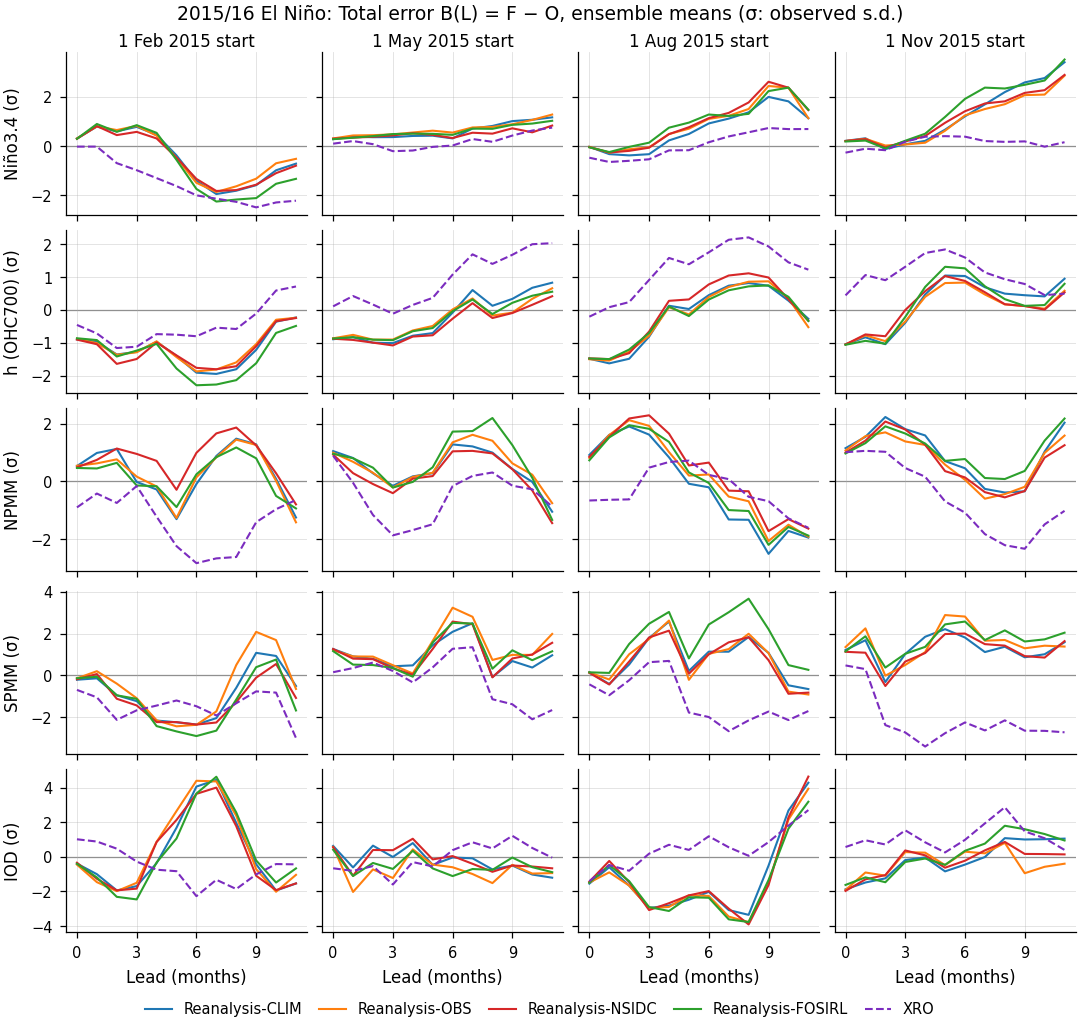

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2015_error_after_start.pdf


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2015_error_after_start.png


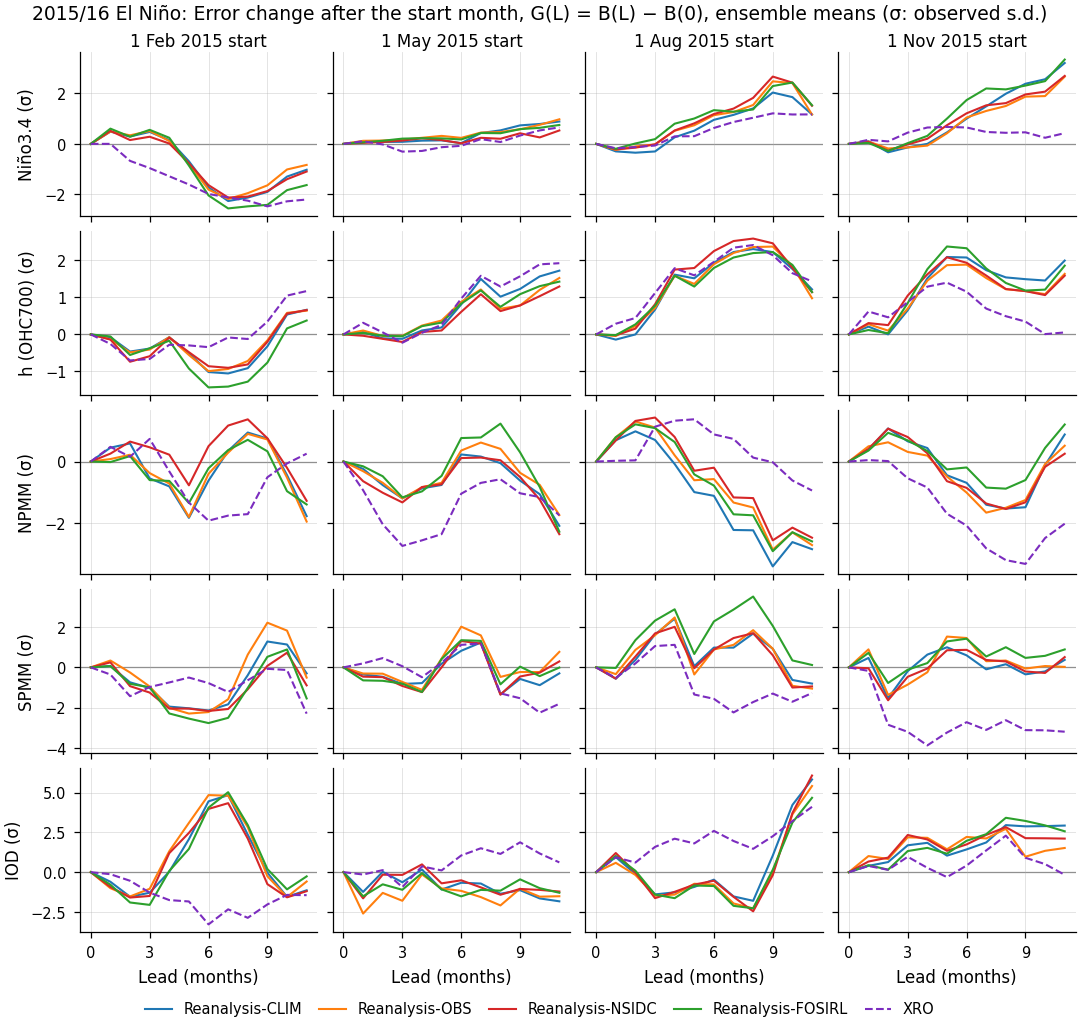

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2026_total_error.pdf


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2026_total_error.png


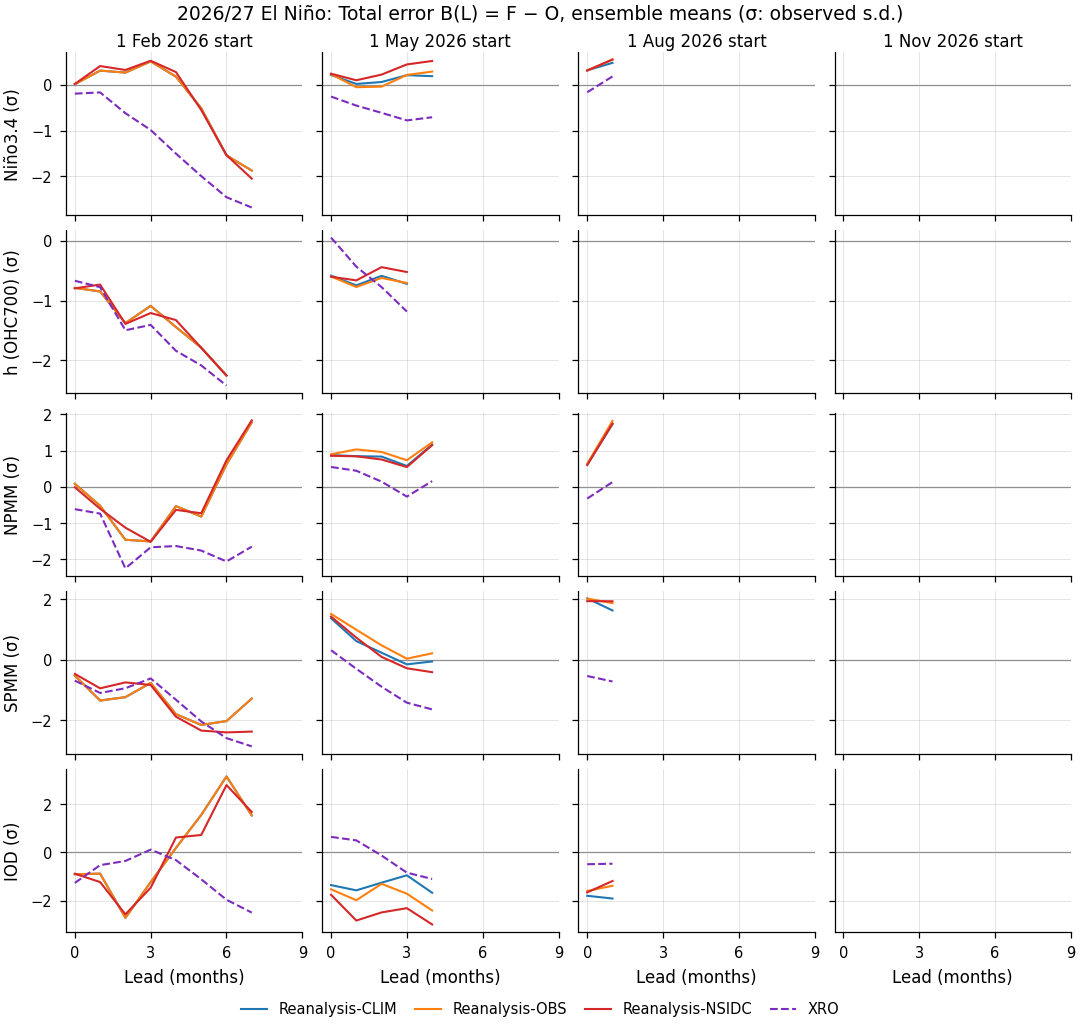

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2026_error_after_start.pdf


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2026_error_after_start.png


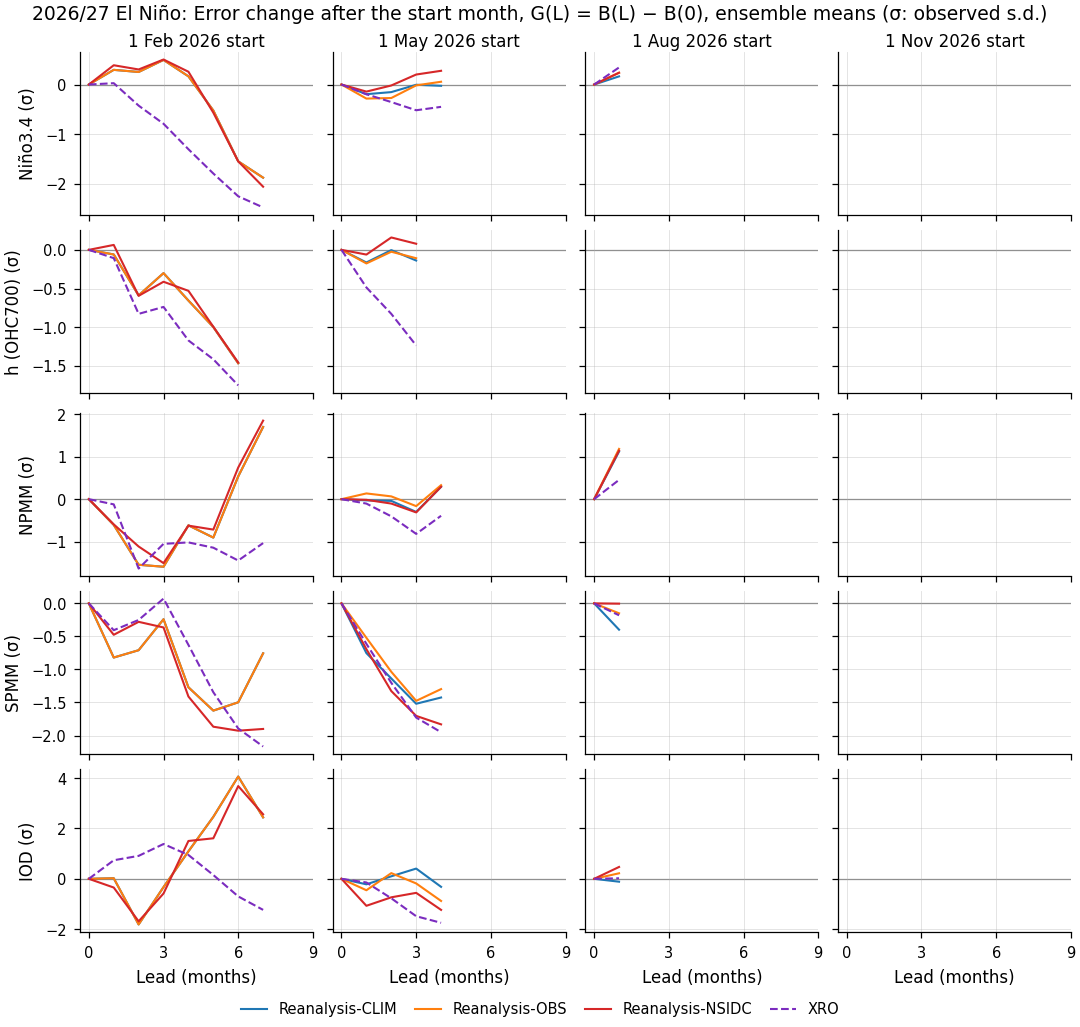

In [6]:
def sources(year, init):
    out = {case: FC_X[(year, case, init)].mean("member") for case in cases_for(year, init)}
    if (year, init) in XRO_FC:
        out["XRO"] = XRO_FC[(year, init)]["det"].sel(lead=slice(0, None))
    return out


def errors(year, init):
    """{source: (B, G)} standardized Datasets over lead."""
    out = {}
    for name, fc in sources(year, init).items():
        b = (fc - rc.match_obs(fc, X)) / SD[year]
        out[name] = (b, b - b.sel(lead=0))
    return out


def source_style(name):
    if name == "XRO":
        return {"color": xc.XRO_STYLE["color"], "ls": "--"}
    return {"color": xc.CASES[name]["color"]}


ERR = {(year, init): errors(year, init) for (year, init) in sorted({(y, i) for (y, _, i) in FC_X})}


def plot_decomposition(year, which):
    inits = [i for i in xc.EVENTS[year]["init_months"] if (year, i) in ERR]
    fig, axes = plt.subplots(len(DECOMP_VARS), len(inits), figsize=(pf.WIDTH["double"], 1.25 * len(DECOMP_VARS) + 0.6),
                             sharex=True, sharey="row", squeeze=False)
    leads = np.arange(DECOMP_LEADS)
    for c, init in enumerate(inits):
        for r, var in enumerate(DECOMP_VARS):
            ax = axes[r, c]
            for name, (b, g) in ERR[(year, init)].items():
                series = (b if which == "B" else g)[var].sel(lead=leads)
                ax.plot(leads, series, lw=1.0, label=name, **source_style(name))
            pf.zero_line(ax)
            ax.grid(True)
            if r == 0:
                ax.set_title(f"1 {xc.MONTH_NAMES[init]} {year} start", loc="center")
            if c == 0:
                ax.set_ylabel(f"{xc.short(var)} (σ)")
            if r == len(DECOMP_VARS) - 1:
                ax.set_xlabel("Lead (months)")
                ax.set_xticks(range(0, DECOMP_LEADS, 3))
    title = "Total error B(L) = F − O" if which == "B" else "Error change after the start month, G(L) = B(L) − B(0)"
    fig.suptitle(f"{xc.EVENTS[year]['label']}: {title}, ensemble means (σ: observed s.d.)")
    pf.legend_below(fig, ax=axes[0, 0], ncol=5)
    return fig


for year in xc.EVENTS:
    for which, tag in (("B", "total_error"), ("G", "error_after_start")):
        fig = plot_decomposition(year, which)
        pf.save(fig, NOTEBOOK, "xro", f"y{year}", tag)
        plt.show()

## 3. Start-month error and first-season evolution error

Left: B(0), the start-month error (for XRO, a one-month forecast error from the observed state).
Right: mean of G(L) over `EVOL_LEADS`, the error accumulated in the first season after the start
month. A cell is large on the left and small on the right when the forecast starts off but then
evolves like the observations. "E3SM" is the mean over the cases' ensemble means (identical runs,
such as Feb 2026 CLIM and OBS, counted once); the cases differ by less than 0.3σ almost everywhere,
and the per-case values are in the CSV files. "n/a": that variable not yet observed; hatched
blocks: start not yet verifiable.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2015_error_decomposition_heatmap.pdf


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2015_error_decomposition_heatmap.png


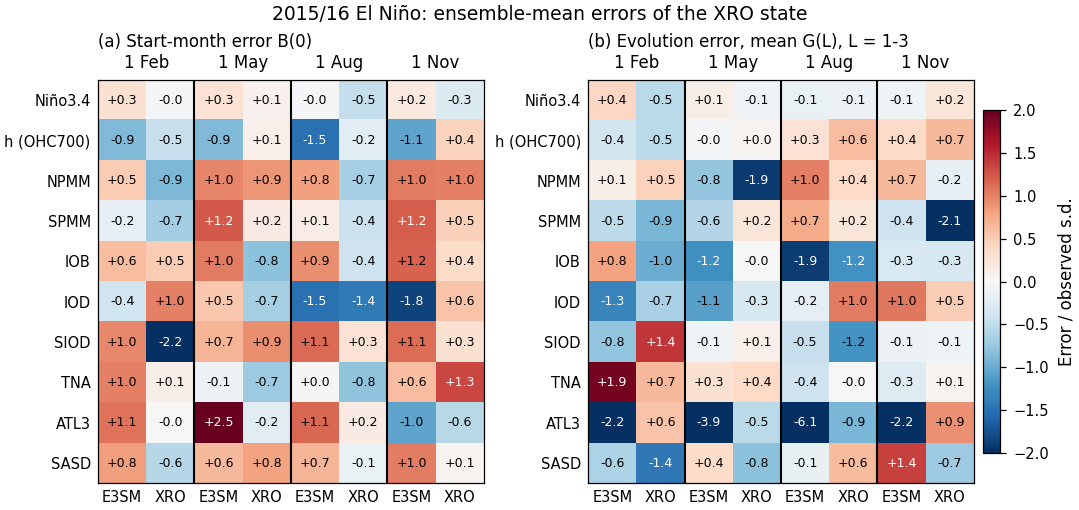

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2026_error_decomposition_heatmap.pdf


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2026_error_decomposition_heatmap.png


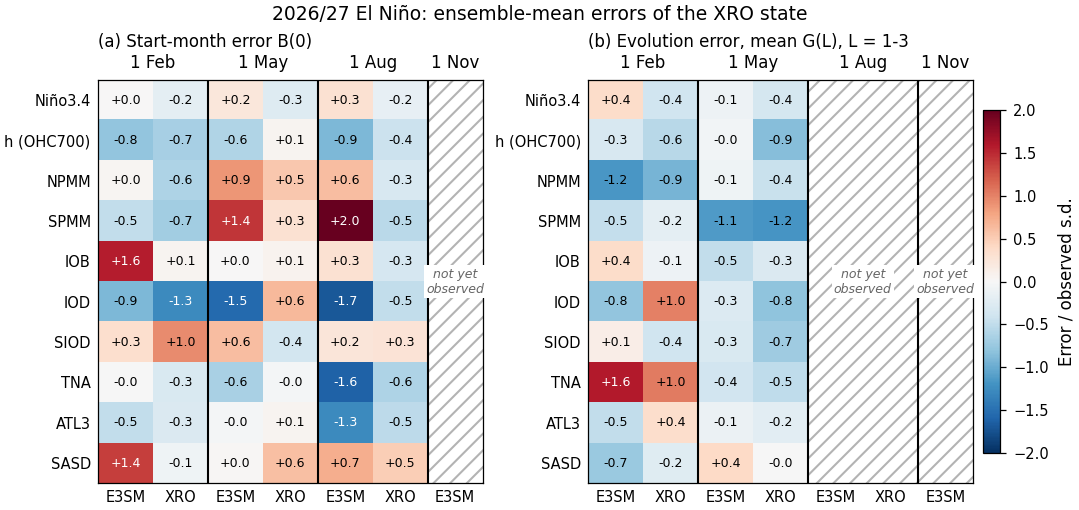

In [7]:
def summary_tables(year):
    cols, init_vals, evol_vals = [], [], []
    for init in xc.EVENTS[year]["init_months"]:
        if (year, init) not in ERR:
            continue
        for name, (b, g) in ERR[(year, init)].items():
            cols.append((init, name))
            init_vals.append([float(b[v].sel(lead=0)) for v in xc.XRO_VARS])
            evol_vals.append([float(g[v].sel(lead=slice(*EVOL_LEADS)).mean("lead", skipna=False)) for v in xc.XRO_VARS])
    index = pd.MultiIndex.from_tuples(cols, names=["init", "source"])
    return (pd.DataFrame(np.array(init_vals).T, index=xc.XRO_VARS, columns=index),
            pd.DataFrame(np.array(evol_vals).T, index=xc.XRO_VARS, columns=index))


def combine_cases(err):
    """Columns (init, "E3SM") = mean over distinct case columns, plus (init, "XRO")."""
    cols, data = [], []
    for init in dict.fromkeys(err.columns.get_level_values("init")):
        sub = err[init]
        cases = [c for c in sub.columns if c in xc.CASES]
        distinct = sub[cases].T.drop_duplicates().T
        cols.append((init, "E3SM"))
        data.append(distinct.mean(axis=1, skipna=False).values)
        if "XRO" in sub:
            cols.append((init, "XRO"))
            data.append(sub["XRO"].values)
    return pd.DataFrame(np.array(data).T, index=err.index, columns=pd.MultiIndex.from_tuples(cols, names=["init", "source"]))


def heatmap(ax, err, year, vmax=2.0):
    im = ax.imshow(err.values, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
    for i in range(err.shape[0]):
        for j in range(err.shape[1]):
            v = err.values[i, j]
            if np.isfinite(v):
                ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=6, color="w" if abs(v) > 0.6 * vmax else "k")
            elif np.isfinite(err.values[:, j]).any():
                ax.text(j, i, "n/a", ha="center", va="center", fontsize=5, color="0.5")
    inits = err.columns.get_level_values("init")
    for j in np.flatnonzero(np.diff(inits)) + 0.5:
        ax.axvline(j, color="k", lw=1.0)
    for init in dict.fromkeys(inits):
        js = np.flatnonzero(inits == init)
        ax.text(js.mean(), -0.7, f"1 {xc.MONTH_NAMES[init]}", ha="center", va="bottom")
        if not np.isfinite(err.values[:, js]).any():
            ax.add_patch(plt.Rectangle((js[0] - 0.5, -0.5), len(js), err.shape[0], fill=False, hatch="///",
                                       edgecolor="0.7", lw=0))
            ax.text(js.mean(), (err.shape[0] - 1) / 2, "not yet\nobserved", ha="center", va="center", color="0.4",
                    style="italic", fontsize=6, bbox={"fc": "w", "ec": "none", "pad": 1})
    ax.set_yticks(range(err.shape[0]), [xc.short(v) for v in err.index])
    ax.set_xticks(range(err.shape[1]), [xc.CASES[s]["short"] if s in xc.CASES else s for _, s in err.columns],
                  rotation=0)
    ax.tick_params(length=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(True)
    return im


for year in xc.EVENTS:
    e_init, e_evol = summary_tables(year)
    e_init.to_csv(OUTDIR / f"XRO_state_start_month_error_y{year}.csv")
    e_evol.to_csv(OUTDIR / f"XRO_state_evolution_error_leads{EVOL_LEADS[0]}-{EVOL_LEADS[1]}_y{year}.csv")
    fig, axes = plt.subplots(1, 2, figsize=(pf.WIDTH["double"], 3.4))
    heatmap(axes[0], combine_cases(e_init), year)
    im = heatmap(axes[1], combine_cases(e_evol), year)
    pf.panel_label(axes[0], 0, "Start-month error B(0)", pad=16)
    pf.panel_label(axes[1], 1, f"Evolution error, mean G(L), L = {EVOL_LEADS[0]}-{EVOL_LEADS[1]}", pad=16)
    cb = fig.colorbar(im, ax=axes, shrink=0.85, pad=0.01)
    cb.set_label("Error / observed s.d.")
    fig.suptitle(f"{xc.EVENTS[year]['label']}: ensemble-mean errors of the XRO state")
    pf.save(fig, NOTEBOOK, "xro", f"y{year}", "error_decomposition_heatmap")
    plt.show()

## 4. Growth from the start month

T(L) − T(0) and h(L) − h(0): each forecast relative to its own start-month value, so start-month
differences drop out and only the evolution is compared. Shading: `SPREAD` range of each case's
members. If E3SM warms faster than observed and than XRO while its *h* changes like the observed,
the extra warming does not come from extra recharge after the start.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2015_growth_from_start.pdf


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2015_growth_from_start.png


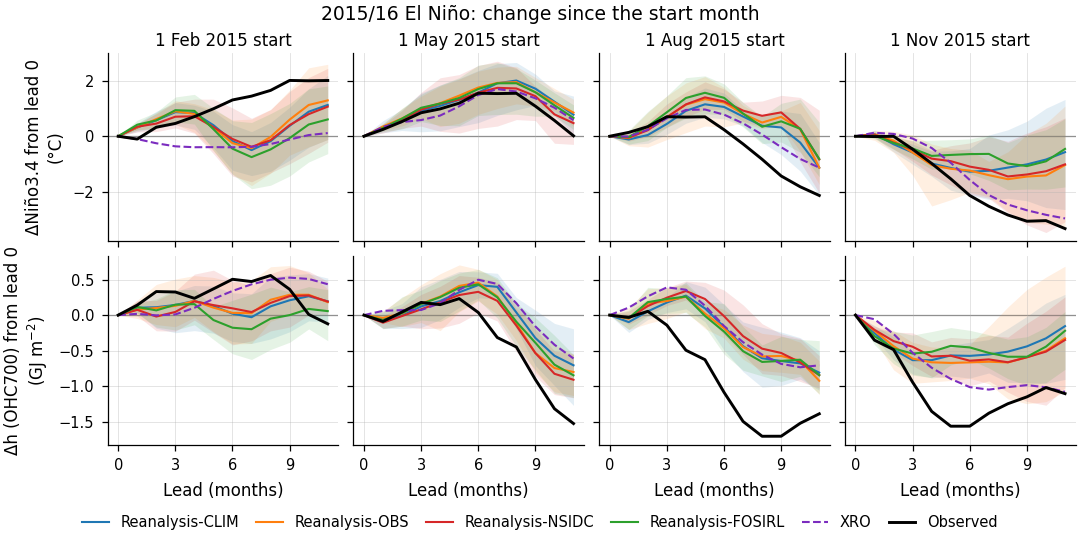

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2026_growth_from_start.pdf


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7c_e3sm_xro_state/figures/fig_xro_y2026_growth_from_start.png


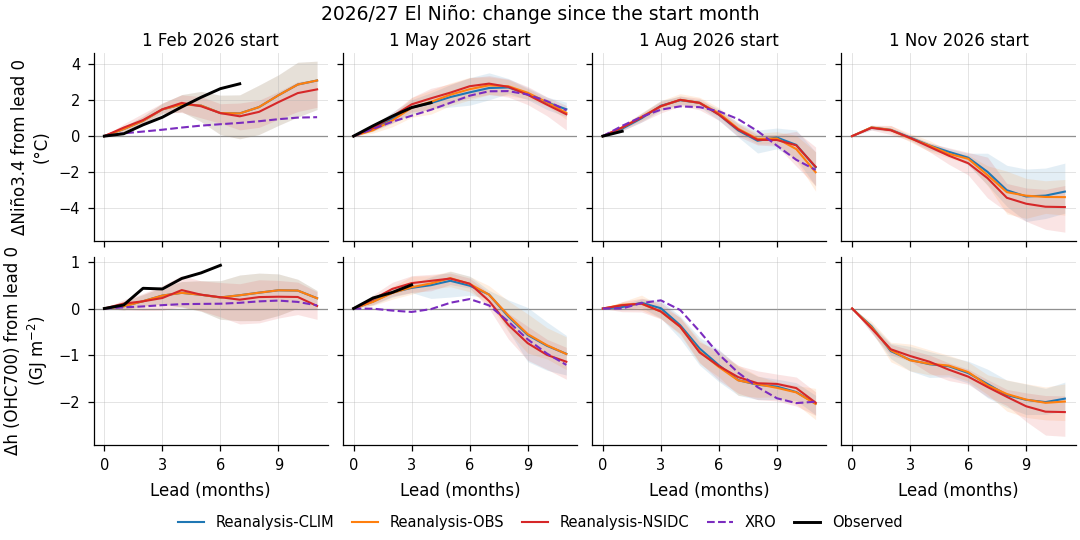

In [8]:
def plot_growth(year):
    inits = [i for i in xc.EVENTS[year]["init_months"] if cases_for(year, i)]
    fig, axes = plt.subplots(2, len(inits), figsize=(pf.WIDTH["double"], 3.6), sharex=True, sharey="row", squeeze=False)
    leads = np.arange(DECOMP_LEADS)
    for c, init in enumerate(inits):
        for r, var in enumerate(["Nino34", "WWV"]):
            ax = axes[r, c]
            for case in cases_for(year, init):
                ds = FC_X[(year, case, init)][var].sel(lead=leads)
                d = ds - ds.sel(lead=0)
                color = xc.CASES[case]["color"]
                ax.fill_between(leads, d.quantile(LO / 100, "member"), d.quantile(HI / 100, "member"), color=color, alpha=0.12, lw=0)
                ax.plot(leads, d.mean("member"), color=color, lw=1.0, label=case)
            if (year, init) in XRO_FC:
                xd = XRO_FC[(year, init)]["det"][var].sel(lead=leads)
                ax.plot(leads, xd - xd.sel(lead=0), color=xc.XRO_STYLE["color"], ls="--", lw=1.0, label="XRO")
            any_case = FC_X[(year, cases_for(year, init)[0], init)].sel(lead=leads)
            o = rc.match_obs(any_case, X)[var]
            ax.plot(leads, o - o.sel(lead=0), color="k", lw=1.4, label="Observed", zorder=5)
            pf.zero_line(ax)
            ax.grid(True)
            if r == 0:
                ax.set_title(f"1 {xc.MONTH_NAMES[init]} {year} start", loc="center")
            else:
                ax.set_xlabel("Lead (months)")
                ax.set_xticks(range(0, DECOMP_LEADS, 3))
            if c == 0:
                ax.set_ylabel(f"Δ{xc.short(var)} from lead 0\n({xc.UNITS[var]})")
    fig.suptitle(f"{xc.EVENTS[year]['label']}: change since the start month")
    pf.legend_below(fig, ax=axes[0, 0], ncol=6)
    return fig


for year in xc.EVENTS:
    fig = plot_growth(year)
    pf.save(fig, NOTEBOOK, "xro", f"y{year}", "growth_from_start")
    plt.show()

## 5. Peak-season summary

Niño3.4 and *h* over each event's peak season: observed (NaN until fully observed), each case's
ensemble mean with the `SPREAD` percentiles of its members, and XRO deterministic and stochastic
(same percentiles). Read XRO values with the amplitude bias of 7a section 6.
"XRO stochastic, calibrated (DJF factor)": Niño3.4 and *h* DJF ranges with the DJF-specific factor of 7a
section 9 (`xc.calibrated_djf`); the monthly factors are used only for the monthly bands in section 1.

In [9]:
rows = []
for (year, init) in sorted({(y, i) for (y, _, i) in FC_X}):
    months = xc.EVENTS[year]["peak_season"]["months"]
    for var in ("Nino34", "WWV"):
        base = {"event": xc.EVENTS[year]["label"], "start": f"1 {xc.MONTH_NAMES[init]} {year}", "variable": xc.short(var),
                "observed": round(float(rc.obs_target_mean(X[var], months)), 2)}
        for case in cases_for(year, init):
            s = rc.target_mean(FC_X[(year, case, init)][var], months)
            if s is None:
                continue
            rows.append({**base, "source": case, "mean": round(float(s.mean("member")), 2),
                         f"{LO}%": round(float(s.quantile(LO / 100, "member")), 2),
                         f"{HI}%": round(float(s.quantile(HI / 100, "member")), 2), "n": int(s.sizes["member"])})
        if (year, init) in XRO_FC:
            fc = XRO_FC[(year, init)]
            rows.append({**base, "source": "XRO deterministic", "mean": round(float(rc.target_mean(fc["det"][var], months)), 2)})
            s = rc.target_mean(fc["stoch"][var], months)
            rows.append({**base, "source": "XRO stochastic", "mean": round(float(s.mean("member")), 2),
                         f"{LO}%": round(float(s.quantile(LO / 100, "member")), 2),
                         f"{HI}%": round(float(s.quantile(HI / 100, "member")), 2), "n": int(s.sizes["member"])})
            if var in xc.CALIBRATION["vars"]:
                s = xc.calibrated_djf(X, year, init, fc["stoch"], var)
                rows.append({**base, "source": "XRO stochastic, calibrated (DJF factor)", "mean": round(float(s.mean("member")), 2),
                             f"{LO}%": round(float(s.quantile(LO / 100, "member")), 2),
                             f"{HI}%": round(float(s.quantile(HI / 100, "member")), 2), "n": int(s.notnull().sum("member"))})
summary = pd.DataFrame(rows)
summary["error"] = (summary["mean"] - summary["observed"]).round(2)
summary.to_csv(OUTDIR / "E3SM_XRO_peak_summary.csv", index=False)
display(summary[summary["variable"] == "Niño3.4"].set_index(["event", "start", "source"]).drop(columns="variable"))

observed  \
event           start      source                                              
2015/16 El Niño 1 Feb 2015 Reanalysis-CLIM                              2.42   
                           Reanalysis-OBS                               2.42   
                           Reanalysis-NSIDC                             2.42   
                           Reanalysis-FOSIRL                            2.42   
                           XRO deterministic                            2.42   
                           XRO stochastic                               2.42   
                           XRO stochastic, calibrated (DJF factor)      2.42   
                1 May 2015 Reanalysis-CLIM                              2.42   
                           Reanalysis-OBS                               2.42   
                           Reanalysis-NSIDC                             2.42   
                           Reanalysis-FOSIRL                            2.42   
                           XRO deterministic                            2.42   
                           XRO stochastic                               2.42   
                           XRO stochastic, calibrated (DJF factor)      2.42   
                1 Aug 2015 Reanalysis-CLIM                              2.42   
                           Reanalysis-OBS                               2.42   
                           Reanalysis-NSIDC                             2.42   
                           Reanalysis-FOSIRL                            2.42   
                           XRO deterministic                            2.42   
                           XRO stochastic                               2.42   
                           XRO stochastic, calibrated (DJF factor)      2.42   
                1 Nov 2015 Reanalysis-CLIM                              2.42   
                           Reanalysis-OBS                               2.42   
                           Reanalysis-NSIDC                             2.42   
                           Reanalysis-FOSIRL                            2.42   
                           XRO deterministic                            2.42   
                           XRO stochastic                               2.42   
                           XRO stochastic, calibrated (DJF factor)      2.42   
2026/27 El Niño 1 Feb 2026 Reanalysis-CLIM                               NaN   
                           Reanalysis-OBS                                NaN   
                           Reanalysis-NSIDC                              NaN   
                           XRO deterministic                             NaN   
                           XRO stochastic                                NaN   
                           XRO stochastic, calibrated (DJF factor)       NaN   
                1 May 2026 Reanalysis-CLIM                               NaN   
                           Reanalysis-OBS                                NaN   
                           Reanalysis-NSIDC                              NaN   
                           XRO deterministic                             NaN   
                           XRO stochastic                                NaN   
                           XRO stochastic, calibrated (DJF factor)       NaN   
                1 Aug 2026 Reanalysis-CLIM                               NaN   
                           Reanalysis-OBS                                NaN   
                           Reanalysis-NSIDC                              NaN   
                           XRO deterministic                             NaN   
                           XRO stochastic                                NaN   
                           XRO stochastic, calibrated (DJF factor)       NaN   
                1 Nov 2026 Reanalysis-CLIM                               NaN   
                           Reanalysis-OBS                                NaN   
                           Reanalysis-NSIDC                         